In [6]:
import numpy as np
import matplotlib.pyplot as plt
from SingleAgent import *

## Theoretical Qlearning values

In [7]:
delta_value = 0.9
epsilon_value = 0.1
P, R, T, S = 0.2, 0.8, 1, 0

The Payoff Matrix:

| **Player A / Player B** | **Cooperate (C)** | **Defect (D)** |
|-------------------------|-------------------|----------------|
| **Cooperate (C)**       | R = 0.8           | S = 0          |
| **Defect (D)**          | T = 1.0           | P = 0.2        |

## Single Run

Final Q-values for Player 1:
[[6.35827457 1.71000851]
 [2.71000642 1.91000811]]
Final Q-values for Player 1 tell us that the player is Collaborating
Number of collaborations: 149, Number of defections: 0
Expected behavior: collaborate more


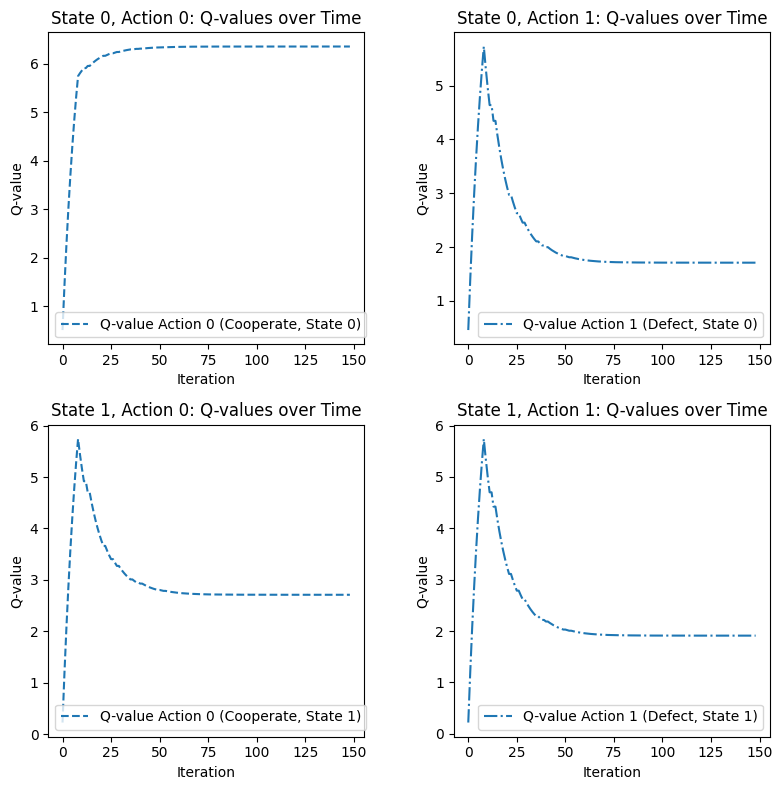

Cooperations: 149, Defections: 0


In [8]:
# Initialize the solver with GrimTrigger_QValues
strategy = GrimTrigger_QValues()
solver = PrisonersDilemmaSolver(
    strategy=strategy,
    e_initial=0.1,
    lambda_val=0.1,
    alpha=0.1,
    delta=delta_value,
    K=500,
    M=10,
    e_decay=1,
    random_uniform=True,
    verbose=True
)

# Run the solver
cooperations, defections, q1_history, mean_q_values, grim_trigger_count_dict = solver.run()
# Check results
print(f"Cooperations: {cooperations}, Defections: {defections}")


In [ ]:
qval_inner_value_iteration = solver.check_value_iteration()

0
1
2
3
4
5
6
7
8
9


In [11]:
dfs = convert_dict_to_mean_df(qval_inner_value_iteration, mean=False)

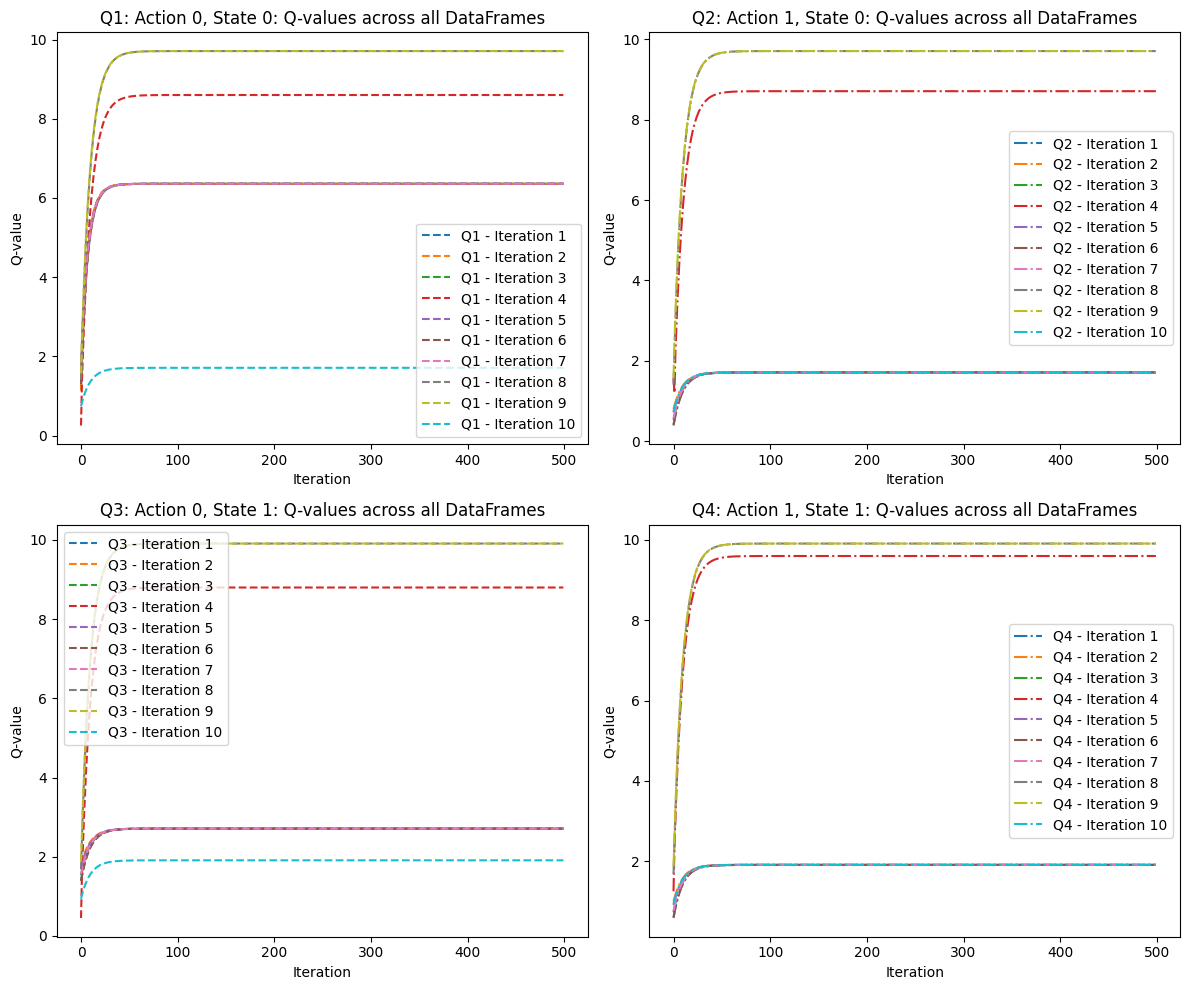

In [ ]:
import matplotlib.pyplot as plt

# Assuming dfs is a list of dataframes
# Create one set of subplots for all Q-values (Q1, Q2, Q3, Q4)
fig, axs = plt.subplots(2, 2, figsize=(12, 10))

# Plot all Q1 values from all DataFrames in a single subplot
for i in range(len(dfs)):
    axs[0, 0].plot(dfs[i]['Q1'], linestyle='--', label=f"Q1 - Iteration {i+1}")
axs[0, 0].set_title("Q1: Action 0, State 0: Q-values across different initializations")
axs[0, 0].set_xlabel("Iteration")
axs[0, 0].set_ylabel("Q-value")
axs[0, 0].legend()

# Plot all Q2 values from all DataFrames in a single subplot
for i in range(len(dfs)):
    axs[0, 1].plot(dfs[i]['Q2'], linestyle='-.', label=f"Q2 - Iteration {i+1}")
axs[0, 1].set_title("Q2: Action 1, State 0: Q-values across different initializations")
axs[0, 1].set_xlabel("Iteration")
axs[0, 1].set_ylabel("Q-value")
axs[0, 1].legend()

# Plot all Q3 values from all DataFrames in a single subplot
for i in range(len(dfs)):
    axs[1, 0].plot(dfs[i]['Q3'], linestyle='--', label=f"Q3 - Iteration {i+1}")
axs[1, 0].set_title("Q3: Action 0, State 1: Q-values across different initializations")
axs[1, 0].set_xlabel("Iteration")
axs[1, 0].set_ylabel("Q-value")
axs[1, 0].legend()

# Plot all Q4 values from all DataFrames in a single subplot
for i in range(len(dfs)):
    axs[1, 1].plot(dfs[i]['Q4'], linestyle='-.', label=f"Q4 - Iteration {i+1}")
axs[1, 1].set_title("Q4: Action 1, State 1: Q-values across different initializations")
axs[1, 1].set_xlabel("Iteration")
axs[1, 1].set_ylabel("Q-value")
axs[1, 1].legend()

# Adjust the layout to avoid overlapping
plt.tight_layout()

# Show the plot for all Q-values combined
plt.show()

#### Added a new feature for counting how many times the player learns how to play GT for each sample. In SingleAgent.py look at the function "check_grim_trigger"

In [ ]:
pd.Series(grim_trigger_count_dict)

0    0
dtype: int64

## Multiple Random Seed

In [ ]:
seeds = random.sample(range(1, 10000), 10)

all_cooperations = []
all_defections = []

for seed in seeds:
    random.seed(seed)
    strategy = GrimTrigger_QValues()  # Or use TitForTat()
    solver = PrisonersDilemmaSolver(strategy, e_initial=epsilon_value, 
                                    lambda_val=0.1, 
                                    alpha=0.05, 
                                    delta=0.9, 
                                    K=100, 
                                    M=10, 
                                    e_decay=0.95, 
                                    verbose=False, plotting = False)
    
    cooperations, defections, q = solver.run()
    all_cooperations.append(cooperations)
    all_defections.append(defections)

all_cooperations = np.array(all_cooperations)
all_defections = np.array(all_defections)

mean_cooperations = np.mean(all_cooperations)
mean_defections = np.mean(all_defections)

print(f"Mean cooperations: {mean_cooperations}")
print(f"Mean defections: {mean_defections}")


NameError: name 'random' is not defined

## Critical Value of delta

In [ ]:
## Should this be changed, putting how many times it learns to play gt instead or number of cooperations?
break

In [ ]:
def analyze_critical_delta(strategy, e_initial, lambda_val, alpha, delta_range, K, M, e_decay, random_uniform=True):
    """
    Analyzes the critical value of delta for which the agent begins cooperating against the Grim Trigger strategy.
    
    Parameters:
        strategy: The opponent strategy (e.g., GrimTrigger).
        e_initial: Initial exploration rate for Q-learning.
        lambda_val: Eligibility decay parameter.
        alpha: Learning rate for Q-learning.
        delta_range: Tuple specifying the range of delta (min, max, step).
        K: Number of iterations per episode.
        M: Number of episodes to train.
        e_decay: Decay rate for exploration rate.
        random_uniform: Whether to initialize Q-values randomly.
    
    Returns:
        A plot of cooperation ratio vs. delta.
    """
    deltas = np.arange(delta_range[0], delta_range[1], delta_range[2])
    cooperation_ratios = []

    for delta in deltas:
        print(f"Running for delta = {delta:.2f}...")  # Verbose output to track progress
        # Initialize the solver for the given delta
        solver = PrisonersDilemmaSolver(
            strategy=strategy,
            e_initial=e_initial,
            lambda_val=lambda_val,
            alpha=alpha,
            delta=delta,
            K=K,
            M=M,
            e_decay=e_decay,
            random_uniform=random_uniform,
            verbose=False,
            plotting=False  # Suppress plotting for individual runs
        )
        # Run the solver and collect results
        cooperations, defections, _, _, checkGT= solver.run()

        # Calculate cooperation ratio
        total_actions = cooperations + defections
        cooperation_ratio = cooperations / total_actions if total_actions > 0 else 0
        cooperation_ratios.append(cooperation_ratio)

    # Plot the cooperation ratio as a function of delta
    plt.figure(figsize=(10, 6))
    plt.plot(deltas, cooperation_ratios, marker='o', linestyle='-', label="Cooperation Ratio")
    plt.axhline(y=0.5, color='r', linestyle='--', label="50% Cooperation Threshold")
    plt.xlabel("Delta (Discount Factor)")
    plt.ylabel("Cooperation Ratio")
    plt.title("Cooperation Ratio vs. Delta in Prisoner's Dilemma")
    plt.legend()
    plt.grid()
    plt.show()

    # Return raw data for further analysis if needed
    return deltas, cooperation_ratios


Running for delta = 0.85...
Number of collaborations: 0, Number of defections: 121
Expected behavior: defect more
Running for delta = 0.90...
Number of collaborations: 0, Number of defections: 126
Expected behavior: collaborate more


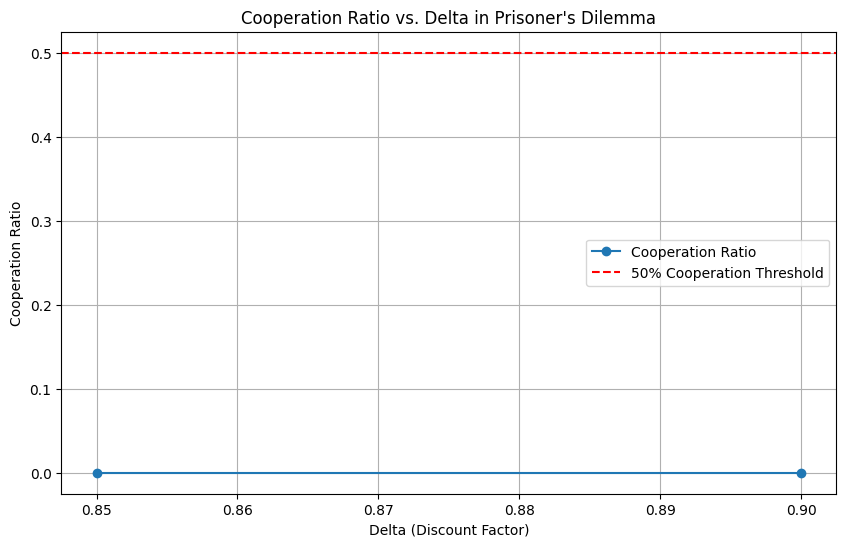

In [ ]:
# Define parameters for the experiment
strategy = GrimTrigger_QValues()
e_initial = epsilon_value
lambda_val = 0.1
alpha = 0.1
delta_range =  (0.85, 0.95, 0.05)# Analyze delta from 0.5 to 1.0 in steps of 0.01
K = 500 # Number of iterations per episode
M = 1  # Number of episodes
e_decay = 1  # Decay rate for exploration
random_uniform = False  # Initialize Q-values randomly

# Run the analysis
deltas, cooperation_ratios = analyze_critical_delta(
    strategy=strategy,
    e_initial=e_initial,
    lambda_val=lambda_val,
    alpha=alpha,
    delta_range=delta_range,
    K=K,
    M=M,
    e_decay=e_decay,
    random_uniform=random_uniform
)
